# Fundamentals of Data Science - Case Studies 2 and 5

## Setup

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "axes.edgecolor": "black",
    "axes.labelcolor": "black",
    "axes.titlecolor": "black",
    "text.color": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
})

MARKERS = ["o", "s", "^", "D", "P", "X", "v"]
SHADES = ["black", "dimgray", "gray", "darkgray", "lightgray", "silver", "white"]
GRAY_MAP = LinearSegmentedColormap.from_list("gray_map", ["#d0d0d0", "#ffffff", "#8a8a8a"])

def save(name):
    plt.savefig(f"figures/{name}.png")
    plt.show()

# Case Study 2: Clustering Analysis of East-West Airlines

## 1. Loading the Data

In [2]:
airline_raw = pd.read_excel("data/EastWestAirlines.xlsx", sheet_name="data")
print(airline_raw.shape)
airline_raw.head()

(3999, 12)


,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


In [3]:
airline_raw.info()
airline_raw.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 3999 entries, 0 to 3998
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   ID#                3999 non-null   int64
 1   Balance            3999 non-null   int64
 2   Qual_miles         3999 non-null   int64
 3   cc1_miles          3999 non-null   int64
 4   cc2_miles          3999 non-null   int64
 5   cc3_miles          3999 non-null   int64
 6   Bonus_miles        3999 non-null   int64
 7   Bonus_trans        3999 non-null   int64
 8   Flight_miles_12mo  3999 non-null   int64
 9   Flight_trans_12    3999 non-null   int64
 10  Days_since_enroll  3999 non-null   int64
 11  Award?             3999 non-null   int64
dtypes: int64(12)
memory usage: 375.0 KB


,count,mean,std,min,25%,50%,75%,max
ID#,3999.0,2014.819455,1160.764358,1.0,1010.5,2016.0,3020.5,4021.0
Balance,3999.0,73601.327582,100775.664958,0.0,18527.5,43097.0,92404.0,1704838.0
Qual_miles,3999.0,144.114529,773.663804,0.0,0.0,0.0,0.0,11148.0
cc1_miles,3999.0,2.059515,1.376919,1.0,1.0,1.0,3.0,5.0
cc2_miles,3999.0,1.014504,0.147650,1.0,1.0,1.0,1.0,3.0
cc3_miles,3999.0,1.012253,0.195241,1.0,1.0,1.0,1.0,5.0
Bonus_miles,3999.0,17144.846212,24150.967826,0.0,1250.0,7171.0,23800.5,263685.0
Bonus_trans,3999.0,11.601900,9.603810,0.0,3.0,12.0,17.0,86.0
Flight_miles_12mo,3999.0,460.055764,1400.209171,0.0,0.0,0.0,311.0,30817.0
Flight_trans_12,3999.0,1.373593,3.793172,0.0,0.0,0.0,1.0,53.0


## 2. Data Preprocessing

### 2.1 Missing Values and Duplicates

In [4]:
print(airline_raw.isnull().sum())
print("Duplicate rows:", airline_raw.duplicated().sum())
print("Duplicate IDs:", airline_raw["ID#"].duplicated().sum())

ID#                  0
Balance              0
Qual_miles           0
cc1_miles            0
cc2_miles            0
cc3_miles            0
Bonus_miles          0
Bonus_trans          0
Flight_miles_12mo    0
Flight_trans_12      0
Days_since_enroll    0
Award?               0
dtype: int64
Duplicate rows: 0
Duplicate IDs: 0


### 2.2 Dropping the ID Column

In [5]:
airline = airline_raw.drop(columns="ID#")
features = [col for col in airline.columns if col != "Award?"]
print(features)

['Balance', 'Qual_miles', 'cc1_miles', 'cc2_miles', 'cc3_miles', 'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12', 'Days_since_enroll']


### 2.3 Outlier Detection

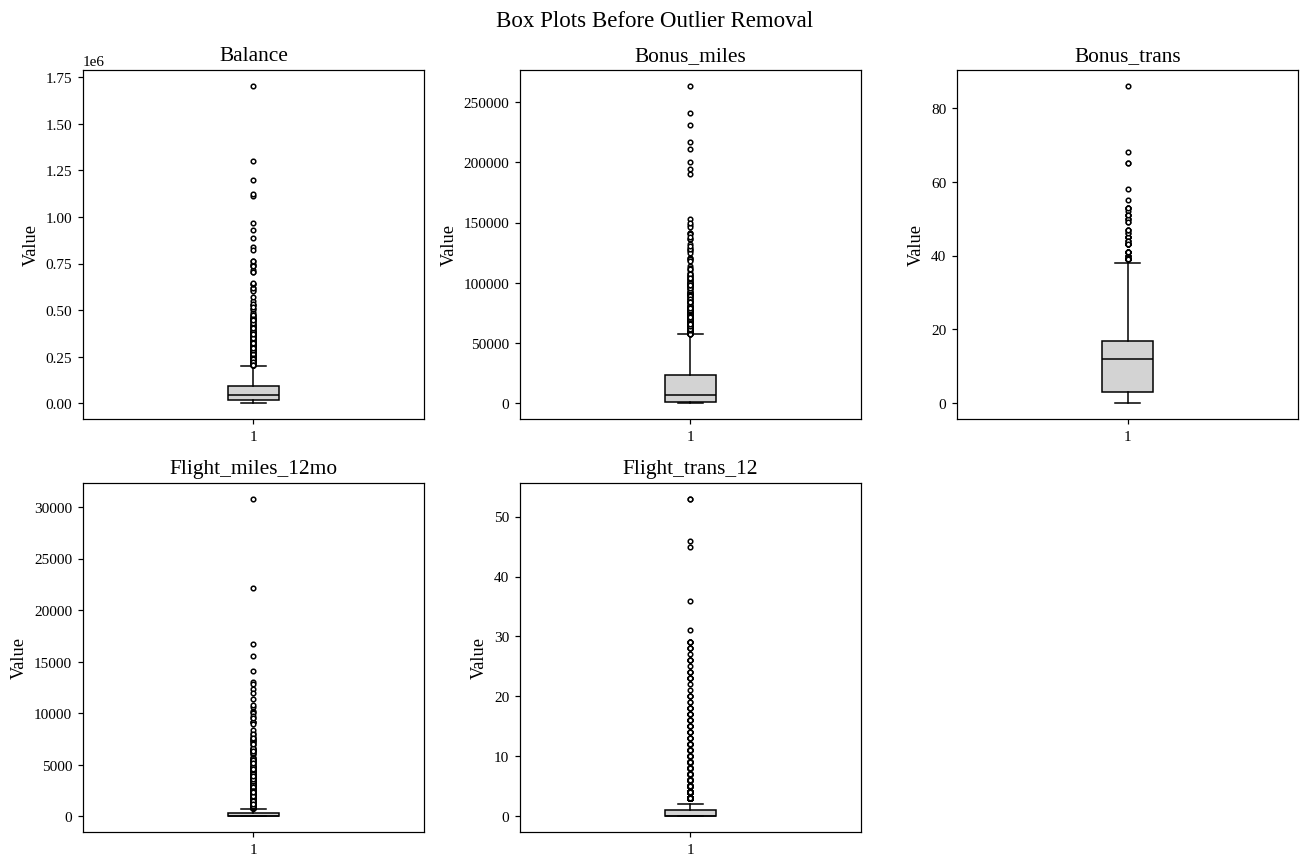

In [6]:
outlier_cols = ["Balance", "Bonus_miles", "Bonus_trans", "Flight_miles_12mo", "Flight_trans_12"]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, col in zip(axes.ravel(), outlier_cols):
    ax.boxplot(airline[col], patch_artist=True,
               boxprops=dict(facecolor="lightgray", color="black"),
               medianprops=dict(color="black"),
               whiskerprops=dict(color="black"),
               capprops=dict(color="black"),
               flierprops=dict(marker="o", markerfacecolor="white", markeredgecolor="black", markersize=3))
    ax.set_title(col)
    ax.set_ylabel("Value")
axes.ravel()[-1].axis("off")
fig.suptitle("Box Plots Before Outlier Removal", fontsize=15)
plt.tight_layout()
save("cs2_boxplots_before")

### 2.4 Outlier Removal

In [7]:
z_scores = (airline[outlier_cols] - airline[outlier_cols].mean()) / airline[outlier_cols].std()
extreme_rows = (z_scores.abs() > 5).any(axis=1)
print("Rows before removal:", len(airline))
print("Extreme rows found:", extreme_rows.sum())
airline_clean = airline[~extreme_rows].reset_index(drop=True)
print("Rows after removal:", len(airline_clean))
airline_clean[outlier_cols].describe().T

Rows before removal: 3999
Extreme rows found: 85
Rows after removal: 3914


,count,mean,std,min,25%,50%,75%,max
Balance,3914.0,67154.665560,75024.006591,0.0,18263.75,41360.0,88547.25,568174.0
Bonus_miles,3914.0,16107.745784,21261.966310,0.0,1221.25,6777.5,23281.00,136704.0
Bonus_trans,3914.0,11.188809,8.998984,0.0,3.00,12.0,16.00,53.0
Flight_miles_12mo,3914.0,346.779254,878.809783,0.0,0.00,0.0,250.00,7450.0
Flight_trans_12,3914.0,1.054676,2.520466,0.0,0.00,0.0,1.00,20.0


### 2.5 Feature Scaling

In [8]:
scaler = StandardScaler()
X = scaler.fit_transform(airline_clean[features])
X_df = pd.DataFrame(X, columns=features)
X_df.describe().T[["mean", "std"]].round(3)

,mean,std
Balance,-0.0,1.0
Qual_miles,0.0,1.0
cc1_miles,-0.0,1.0
cc2_miles,0.0,1.0
cc3_miles,-0.0,1.0
Bonus_miles,-0.0,1.0
Bonus_trans,0.0,1.0
Flight_miles_12mo,0.0,1.0
Flight_trans_12,0.0,1.0
Days_since_enroll,0.0,1.0


## 3. Exploratory Data Analysis

### 3.1 Distribution of Numeric Features

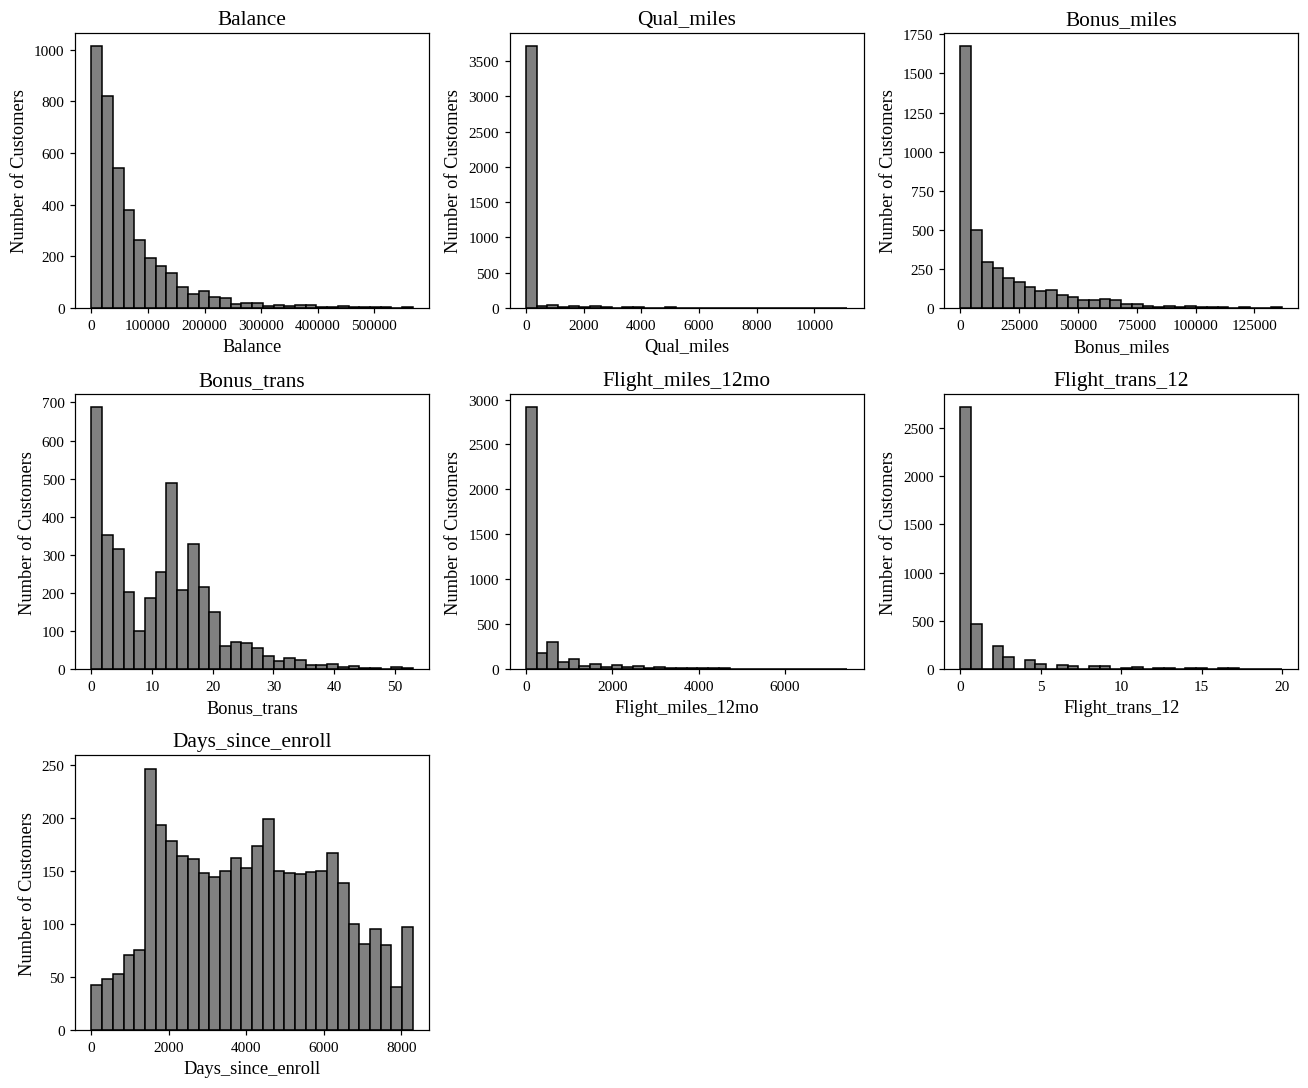

Balance              2.44
Qual_miles           7.78
Bonus_miles          1.95
Bonus_trans          0.87
Flight_miles_12mo    3.93
Flight_trans_12      3.66
Days_since_enroll    0.12
dtype: float64


In [9]:
numeric_cols = ["Balance", "Qual_miles", "Bonus_miles", "Bonus_trans", "Flight_miles_12mo", "Flight_trans_12", "Days_since_enroll"]
fig, axes = plt.subplots(3, 3, figsize=(12, 10))
for ax, col in zip(axes.ravel(), numeric_cols):
    ax.hist(airline_clean[col], bins=30, color="gray", edgecolor="black")
    ax.set_title(f"{col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of Customers")
axes.ravel()[-1].axis("off")
axes.ravel()[-2].axis("off")
plt.tight_layout()
save("cs2_histograms")
print(airline_clean[numeric_cols].skew().round(2))

### 3.2 Credit Card Mile Categories

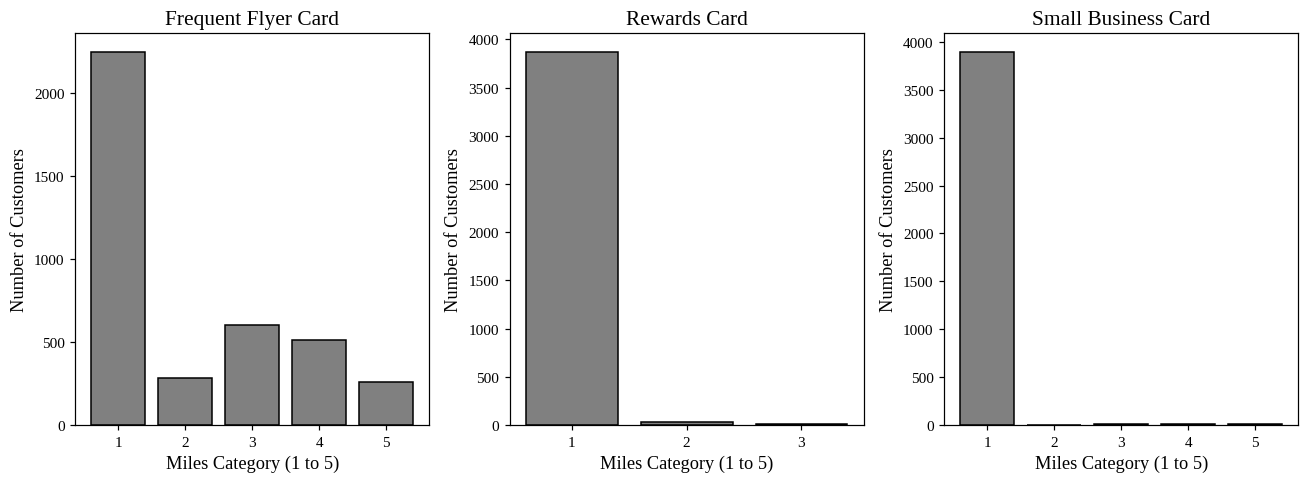

   cc1_miles  cc2_miles  cc3_miles
1      0.575      0.989      0.996
2      0.072      0.007      0.001
3      0.155      0.004      0.001
4      0.132        NaN      0.001
5      0.066        NaN      0.001


In [10]:
card_cols = ["cc1_miles", "cc2_miles", "cc3_miles"]
card_titles = ["Frequent Flyer Card", "Rewards Card", "Small Business Card"]
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))
for ax, col, title in zip(axes, card_cols, card_titles):
    counts = airline_clean[col].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color="gray", edgecolor="black")
    ax.set_title(title)
    ax.set_xlabel("Miles Category (1 to 5)")
    ax.set_ylabel("Number of Customers")
plt.tight_layout()
save("cs2_card_categories")
print(airline_clean[card_cols].apply(lambda s: s.value_counts(normalize=True).round(3)))

### 3.3 Award Status

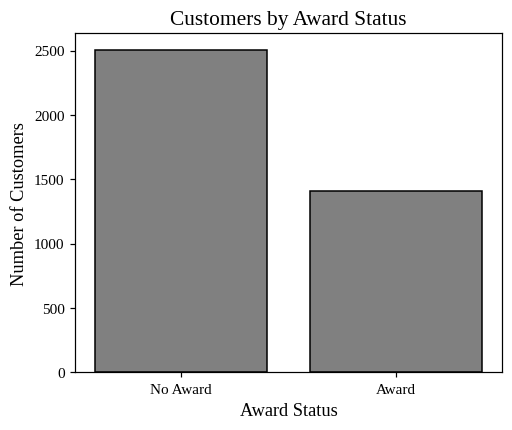

Award?
0    2508
1    1406
Name: count, dtype: int64


In [11]:
award_counts = airline_clean["Award?"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["No Award", "Award"], award_counts.values, color="gray", edgecolor="black")
ax.set_title("Customers by Award Status")
ax.set_xlabel("Award Status")
ax.set_ylabel("Number of Customers")
save("cs2_award_status")
print(award_counts)

### 3.4 Correlation Heatmap

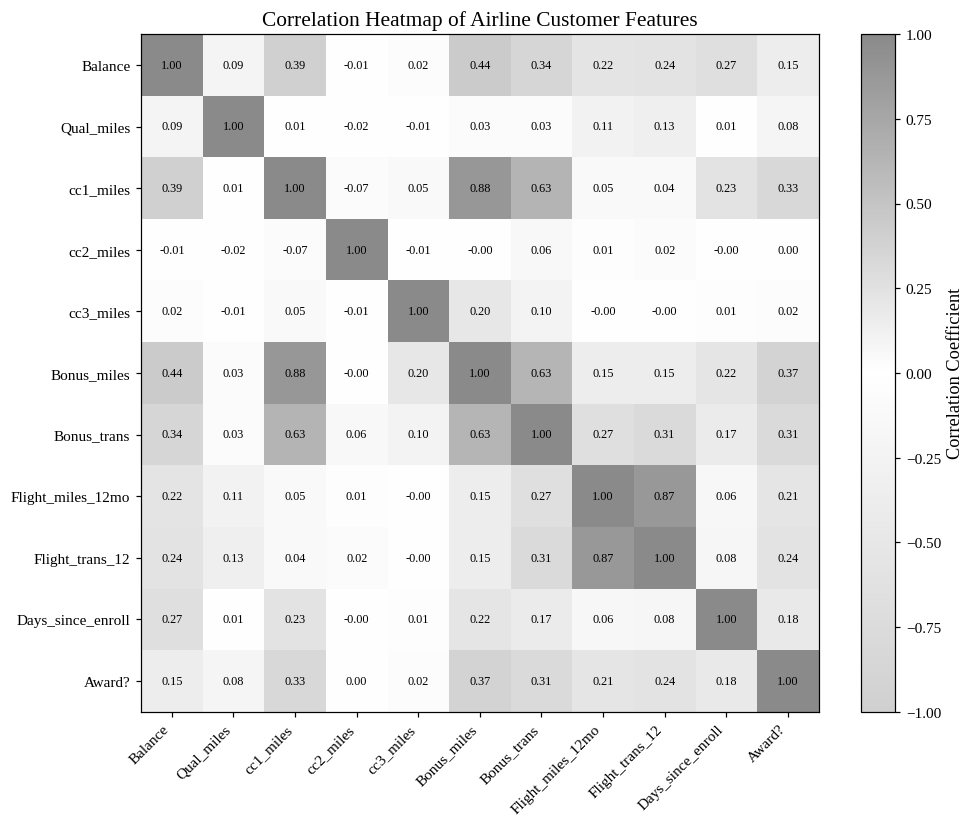

In [12]:
corr_airline = airline_clean[features + ["Award?"]].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr_airline, cmap=GRAY_MAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_airline)))
ax.set_yticks(range(len(corr_airline)))
ax.set_xticklabels(corr_airline.columns, rotation=45, ha="right")
ax.set_yticklabels(corr_airline.columns)
for i in range(len(corr_airline)):
    for j in range(len(corr_airline)):
        ax.text(j, i, f"{corr_airline.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlation Heatmap of Airline Customer Features")
fig.colorbar(im, ax=ax, label="Correlation Coefficient")
save("cs2_heatmap")

### 3.5 Relationships Between Key Features

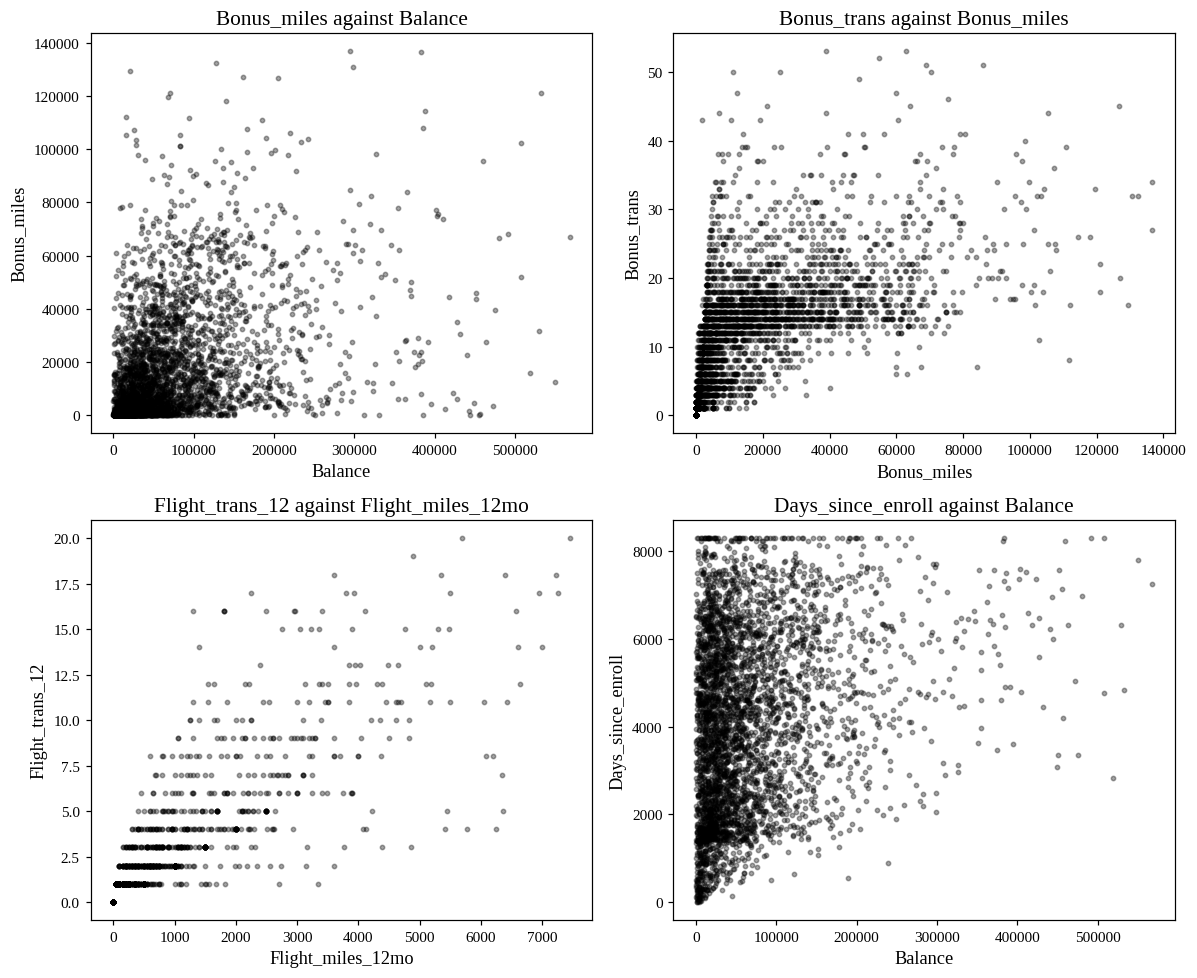

In [13]:
pairs = [("Balance", "Bonus_miles"), ("Bonus_miles", "Bonus_trans"), ("Flight_miles_12mo", "Flight_trans_12"), ("Balance", "Days_since_enroll")]
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (a, b) in zip(axes.ravel(), pairs):
    ax.scatter(airline_clean[a], airline_clean[b], s=8, color="black", alpha=0.35)
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f"{b} against {a}")
plt.tight_layout()
save("cs2_scatter_pairs")

## 4. K-Means Clustering

### 4.1 Elbow Curve and Silhouette Scores

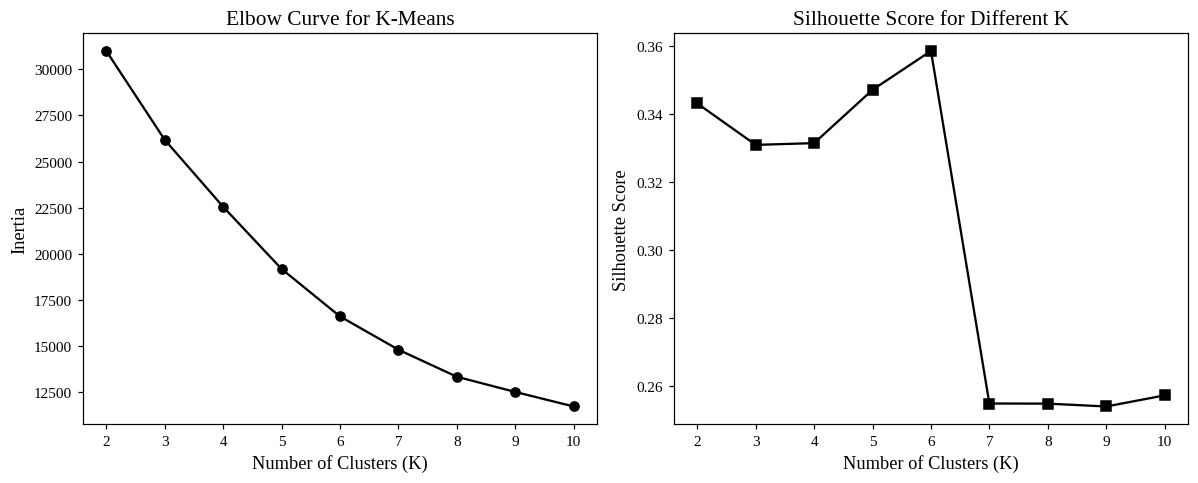

 K  Inertia  Silhouette
 2  30986.9       0.343
 3  26177.7       0.331
 4  22552.4       0.331
 5  19189.1       0.347
 6  16617.9       0.358
 7  14817.6       0.255
 8  13352.8       0.255
 9  12530.0       0.254
10  11742.7       0.257


In [14]:
k_values = range(2, 11)
inertia_list = []
silhouette_list = []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia_list.append(model.inertia_)
    silhouette_list.append(silhouette_score(X, model.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(list(k_values), inertia_list, marker="o", color="black")
axes[0].set_title("Elbow Curve for K-Means")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_values), silhouette_list, marker="s", color="black")
axes[1].set_title("Silhouette Score for Different K")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
plt.tight_layout()
save("cs2_kmeans_elbow")
print(pd.DataFrame({"K": list(k_values), "Inertia": np.round(inertia_list, 1), "Silhouette": np.round(silhouette_list, 3)}).to_string(index=False))

### 4.2 Final K-Means Model

In [15]:
K_FINAL = 3
kmeans = KMeans(n_clusters=K_FINAL, n_init=10, random_state=42).fit(X)
airline_clean["KMeans"] = kmeans.labels_
kmeans_silhouette = silhouette_score(X, kmeans.labels_)
print("Silhouette score:", round(kmeans_silhouette, 3))
print(airline_clean["KMeans"].value_counts().sort_index())

Silhouette score: 0.331
KMeans
0    2404
1     256
2    1254
Name: count, dtype: int64


## 5. Hierarchical Clustering

### 5.1 Dendrogram

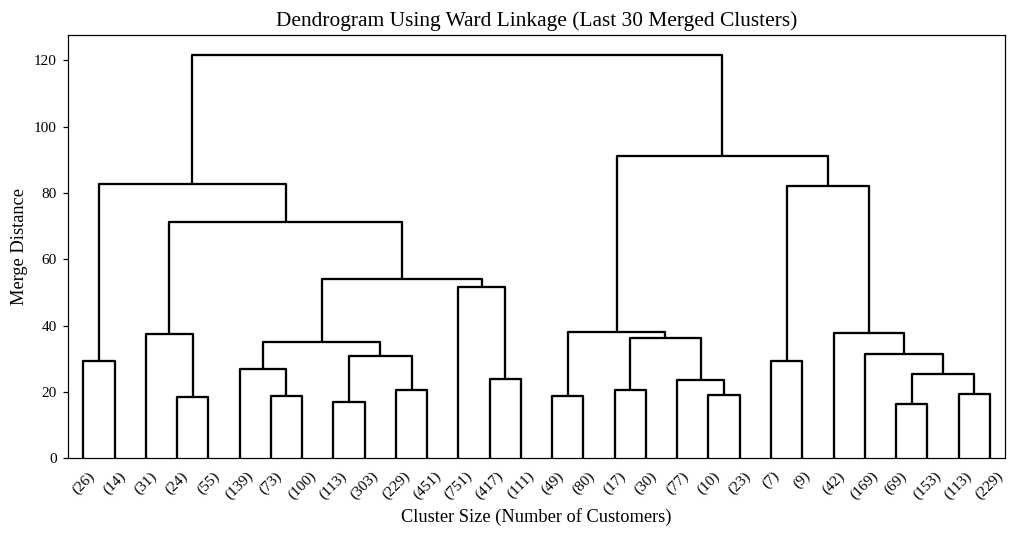

In [16]:
Z = linkage(X, method="ward")
fig, ax = plt.subplots(figsize=(11, 5))
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=0, above_threshold_color="black", ax=ax)
ax.set_title("Dendrogram Using Ward Linkage (Last 30 Merged Clusters)")
ax.set_xlabel("Cluster Size (Number of Customers)")
ax.set_ylabel("Merge Distance")
save("cs2_dendrogram")

### 5.2 Comparing Linkage Methods

In [17]:
linkage_rows = []
for method in ["ward", "complete", "average", "single"]:
    for k in [3, 4, 5]:
        labels = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(X)
        sizes = np.bincount(labels)
        linkage_rows.append({
            "Linkage": method,
            "Clusters": k,
            "Silhouette": round(silhouette_score(X, labels), 3),
            "Largest Cluster Share": round(sizes.max() / len(labels), 3),
        })
linkage_table = pd.DataFrame(linkage_rows)
print(linkage_table.to_string(index=False))

 Linkage  Clusters  Silhouette  Largest Cluster Share
    ward         3       0.334                  0.725
    ward         4       0.352                  0.715
    ward         5       0.339                  0.715
complete         3       0.566                  0.983
complete         4       0.577                  0.973
complete         5       0.579                  0.971
 average         3       0.723                  0.995
 average         4       0.656                  0.984
 average         5       0.646                  0.984
  single         3       0.567                  0.989
  single         4       0.550                  0.989
  single         5       0.558                  0.986


### 5.3 Final Hierarchical Model

In [18]:
hier = AgglomerativeClustering(n_clusters=K_FINAL, linkage="ward")
airline_clean["Hierarchical"] = hier.fit_predict(X)
hier_silhouette = silhouette_score(X, airline_clean["Hierarchical"])
print("Silhouette score:", round(hier_silhouette, 3))
print(airline_clean["Hierarchical"].value_counts().sort_index())

Silhouette score: 0.334
Hierarchical
0    2837
1     791
2     286
Name: count, dtype: int64


## 6. DBSCAN Clustering

### 6.1 K-Distance Plot

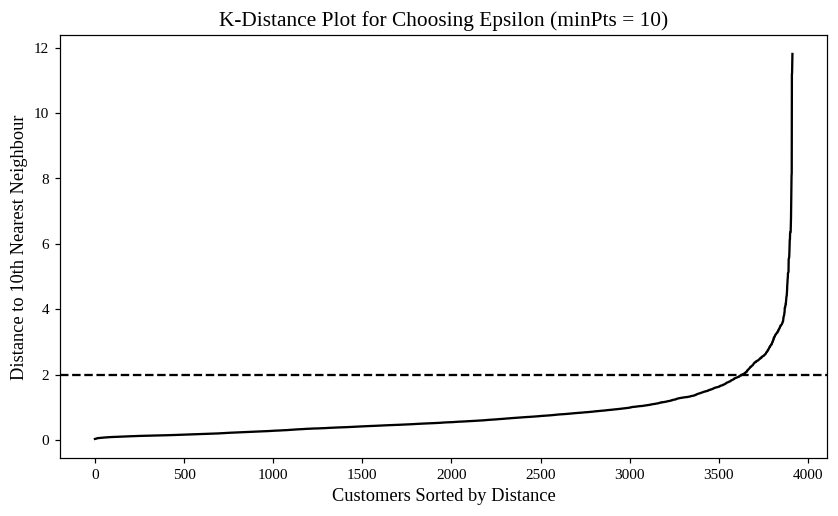

In [19]:
MIN_PTS = 10
neighbors = NearestNeighbors(n_neighbors=MIN_PTS).fit(X)
distances, _ = neighbors.kneighbors(X)
k_distances = np.sort(distances[:, -1])
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(k_distances, color="black")
ax.axhline(2.0, color="black", linestyle="--")
ax.set_title("K-Distance Plot for Choosing Epsilon (minPts = 10)")
ax.set_xlabel("Customers Sorted by Distance")
ax.set_ylabel("Distance to 10th Nearest Neighbour")
save("cs2_kdistance")

### 6.2 Parameter Search

In [20]:
dbscan_rows = []
for eps in [1.0, 1.5, 2.0, 2.5, 3.0]:
    for min_pts in [10, 20]:
        labels = DBSCAN(eps=eps, min_samples=min_pts).fit_predict(X)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_share = (labels == -1).mean()
        if n_clusters > 1:
            score = silhouette_score(X[labels != -1], labels[labels != -1])
        else:
            score = np.nan
        dbscan_rows.append({
            "Epsilon": eps,
            "minPts": min_pts,
            "Clusters": n_clusters,
            "Noise Share": round(noise_share, 3),
            "Silhouette": round(score, 3) if not np.isnan(score) else np.nan,
        })
dbscan_table = pd.DataFrame(dbscan_rows)
print(dbscan_table.to_string(index=False))

 Epsilon  minPts  Clusters  Noise Share  Silhouette
     1.0      10         2        0.173       0.651
     1.0      20         1        0.198         NaN
     1.5      10         2        0.086       0.615
     1.5      20         1        0.109         NaN
     2.0      10         3        0.044       0.594
     2.0      20         2        0.057       0.600
     2.5      10         3        0.024       0.577
     2.5      20         2        0.035       0.584
     3.0      10         3        0.014       0.571
     3.0      20         2        0.021       0.575


### 6.3 Final DBSCAN Model

In [21]:
dbscan = DBSCAN(eps=2.0, min_samples=10).fit(X)
airline_clean["DBSCAN"] = dbscan.labels_
mask = dbscan.labels_ != -1
dbscan_silhouette = silhouette_score(X[mask], dbscan.labels_[mask])
print("Silhouette score (without noise):", round(dbscan_silhouette, 3))
print(airline_clean["DBSCAN"].value_counts().sort_index())

Silhouette score (without noise): 0.594
DBSCAN
-1     174
 0    3708
 1      22
 2      10
Name: count, dtype: int64


## 7. Visualizing the Clusters

### 7.1 Principal Component Projection

Explained variance: [0.304 0.176]
Total: 0.481


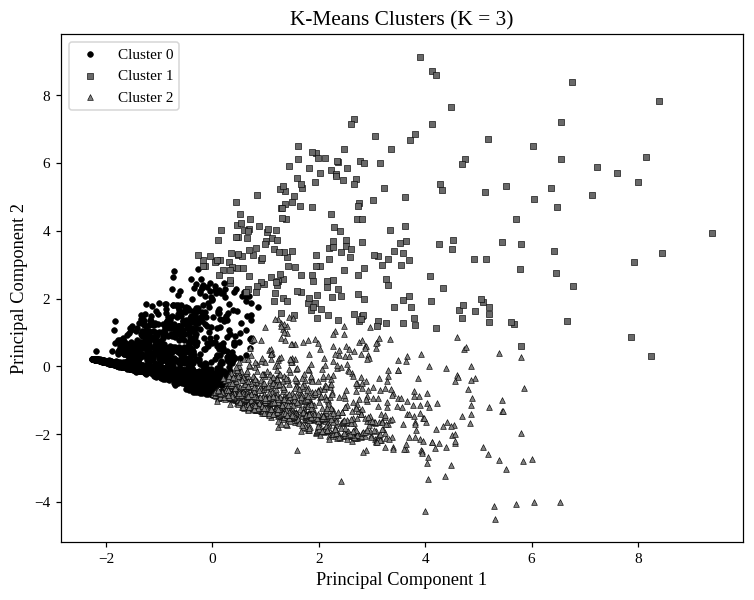

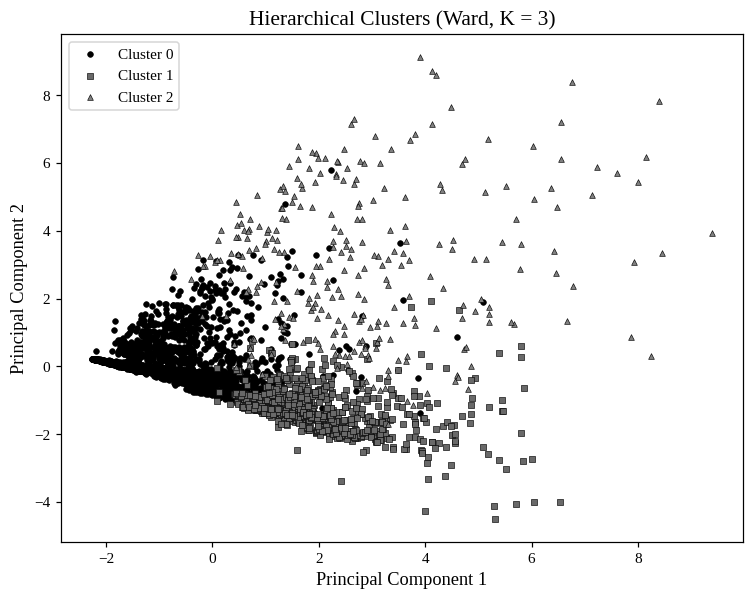

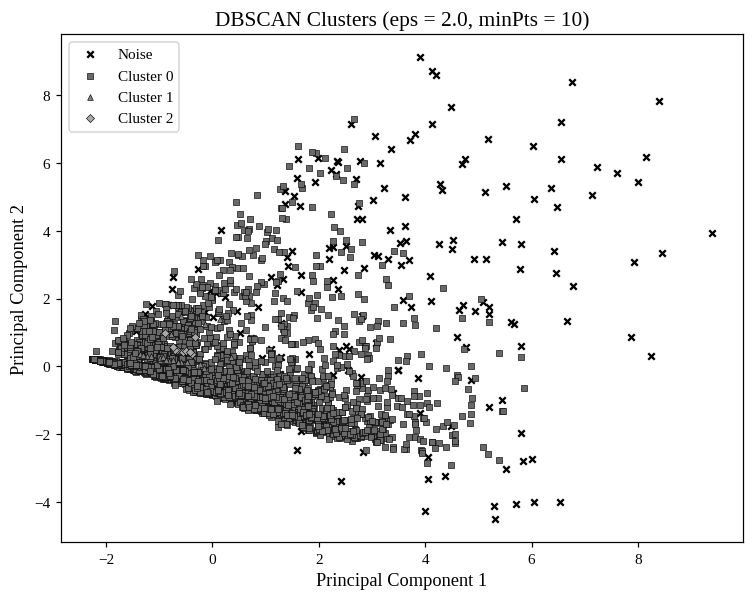

In [22]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)
print("Explained variance:", np.round(pca.explained_variance_ratio_, 3))
print("Total:", round(pca.explained_variance_ratio_.sum(), 3))

def plot_clusters(ax, labels, title):
    for idx, lab in enumerate(sorted(set(labels))):
        pts = X_pca[labels == lab]
        name = "Noise" if lab == -1 else f"Cluster {lab}"
        marker = "x" if lab == -1 else MARKERS[idx % len(MARKERS)]
        shade = "black" if lab == -1 else SHADES[idx % 5]
        if marker == "x":
            ax.scatter(pts[:, 0], pts[:, 1], s=18, c="black", marker="x", label=name)
        else:
            ax.scatter(pts[:, 0], pts[:, 1], s=14, c=shade, marker=marker, edgecolors="black", linewidths=0.4, label=name)
    ax.set_title(title)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.legend(fontsize=10)

for labels, title, name in [
    (airline_clean["KMeans"].values, "K-Means Clusters (K = 3)", "cs2_plot_kmeans"),
    (airline_clean["Hierarchical"].values, "Hierarchical Clusters (Ward, K = 3)", "cs2_plot_hierarchical"),
    (airline_clean["DBSCAN"].values, "DBSCAN Clusters (eps = 2.0, minPts = 10)", "cs2_plot_dbscan"),
]:
    fig, ax = plt.subplots(figsize=(8, 6))
    plot_clusters(ax, labels, title)
    save(name)

## 8. Cluster Profiling

In [23]:
profile_cols = ["Balance", "Qual_miles", "cc1_miles", "Bonus_miles", "Bonus_trans", "Flight_miles_12mo", "Flight_trans_12", "Days_since_enroll", "Award?"]
for algo in ["KMeans", "Hierarchical", "DBSCAN"]:
    print("\n" + algo)
    prof = airline_clean.groupby(algo)[profile_cols].mean().round(2)
    prof.insert(0, "Customers", airline_clean[algo].value_counts().sort_index())
    print(prof.to_string())


KMeans
        Customers    Balance  Qual_miles  cc1_miles  Bonus_miles  Bonus_trans  Flight_miles_12mo  Flight_trans_12  Days_since_enroll  Award?
KMeans                                                                                                                                      
0            2404   40125.90      106.74       1.18      4204.25         6.50             129.06             0.44            3685.36    0.23
1             256  123939.05      573.55       2.05     23986.38        20.01            3063.27             8.83            4461.62    0.67
2            1254  107378.22      101.25       3.68     37319.14        18.38             209.60             0.65            4821.28    0.54

Hierarchical
              Customers    Balance  Qual_miles  cc1_miles  Bonus_miles  Bonus_trans  Flight_miles_12mo  Flight_trans_12  Days_since_enroll  Award?
Hierarchical                                                                                                                  

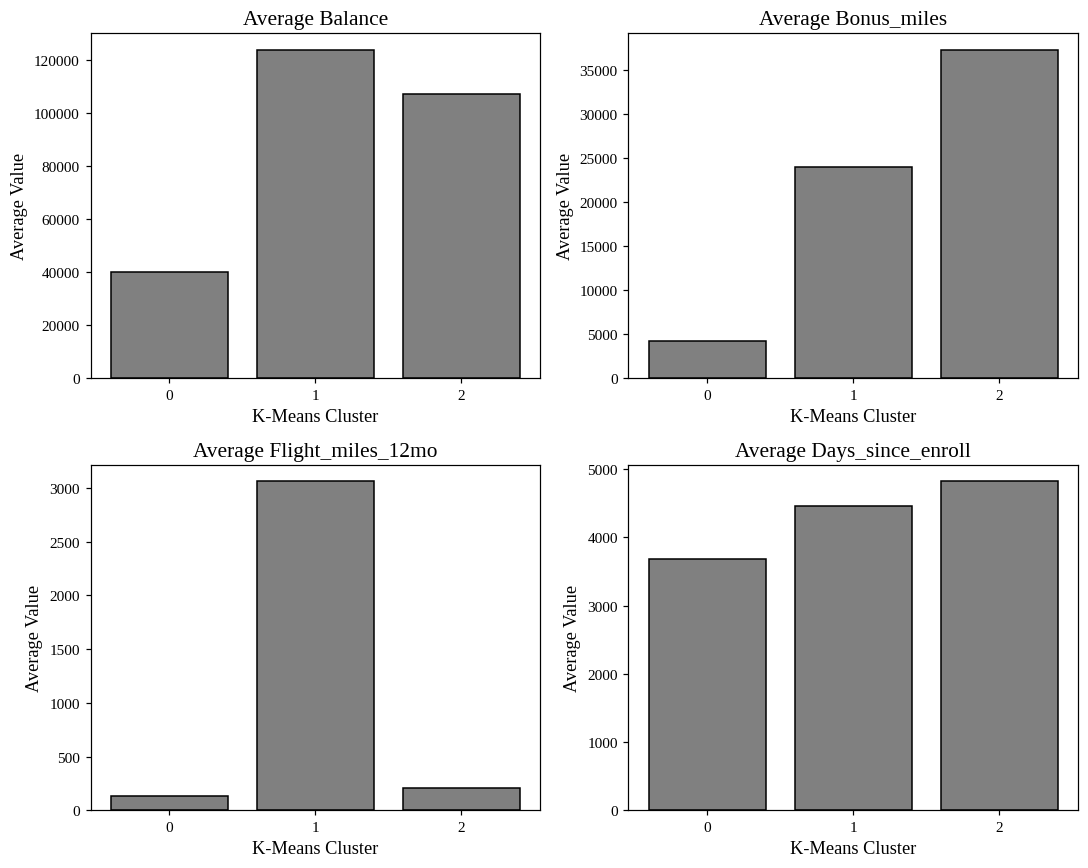

In [24]:
kmeans_profile = airline_clean.groupby("KMeans")[["Balance", "Bonus_miles", "Flight_miles_12mo", "Days_since_enroll"]].mean()
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, col in zip(axes.ravel(), kmeans_profile.columns):
    ax.bar(kmeans_profile.index.astype(str), kmeans_profile[col], color="gray", edgecolor="black")
    ax.set_title(f"Average {col}")
    ax.set_xlabel("K-Means Cluster")
    ax.set_ylabel("Average Value")
plt.tight_layout()
save("cs2_kmeans_profile")

## 9. Evaluation Summary

In [25]:
summary = pd.DataFrame({
    "Algorithm": ["K-Means", "Hierarchical (Ward)", "DBSCAN"],
    "Clusters": [K_FINAL, K_FINAL, 3],
    "Silhouette": [round(kmeans_silhouette, 3), round(hier_silhouette, 3), round(dbscan_silhouette, 3)],
    "Noise Points": [0, 0, int((dbscan.labels_ == -1).sum())],
})
print(summary.to_string(index=False))

          Algorithm  Clusters  Silhouette  Noise Points
            K-Means         3       0.331             0
Hierarchical (Ward)         3       0.334             0
             DBSCAN         3       0.594           174


# Case Study 5: Wine Quality Assessment

## 1. Loading the Data

In [26]:
red = pd.read_csv("data/winequality-red.csv", sep=";")
white = pd.read_csv("data/winequality-white.csv", sep=";")
red["type"] = "red"
white["type"] = "white"
wine = pd.concat([red, white], ignore_index=True)
print(red.shape, white.shape, wine.shape)
wine.head()

(1599, 13) (4898, 13) (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [27]:
wine.info()
print(wine.isnull().sum().sum())
print("Duplicate rows:", wine.duplicated().sum())
wine.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB
0
Duplicate rows: 1177


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


In [28]:
attributes = ["fixed acidity", "volatile acidity", "citric acid", "residual sugar", "chlorides",
              "free sulfur dioxide", "total sulfur dioxide", "density", "pH", "sulphates", "alcohol"]

## Task 1: Statistical Analysis

### 1a. Descriptive Statistics

In [29]:
selected = ["alcohol", "volatile acidity", "residual sugar"]
stats_rows = []
for col in selected:
    stats_rows.append({
        "Attribute": col,
        "Mean": wine[col].mean(),
        "Median": wine[col].median(),
        "Mode": wine[col].mode()[0],
        "Std Dev": wine[col].std(),
        "Skewness": wine[col].skew(),
    })
stats_table = pd.DataFrame(stats_rows).set_index("Attribute").round(3)
print(stats_table.to_string())

                    Mean  Median  Mode  Std Dev  Skewness
Attribute                                                
alcohol           10.492   10.30  9.50    1.193     0.566
volatile acidity   0.340    0.29  0.28    0.165     1.495
residual sugar     5.443    3.00  2.00    4.758     1.435


### 1b. Relative Variability

In [30]:
cv_table = pd.DataFrame({
    "Mean": wine[selected].mean(),
    "Std Dev": wine[selected].std(),
})
cv_table["CV (%)"] = cv_table["Std Dev"] / cv_table["Mean"] * 100
print(cv_table.round(3).to_string())
print("Highest relative variability:", cv_table["CV (%)"].idxmax())

                    Mean  Std Dev  CV (%)
alcohol           10.492    1.193  11.368
volatile acidity   0.340    0.165  48.470
residual sugar     5.443    4.758  87.408
Highest relative variability: residual sugar


### 1c. Alcohol and Quality Correlation

In [31]:
r_value, p_value = stats.pearsonr(wine["alcohol"], wine["quality"])
print("Pearson r:", round(r_value, 4))
print("p-value:", p_value)

Pearson r: 0.4443
p-value: 1.49754444766e-312


## Task 2: Exploratory Data Analysis

### 2a. Histogram of Quality Scores

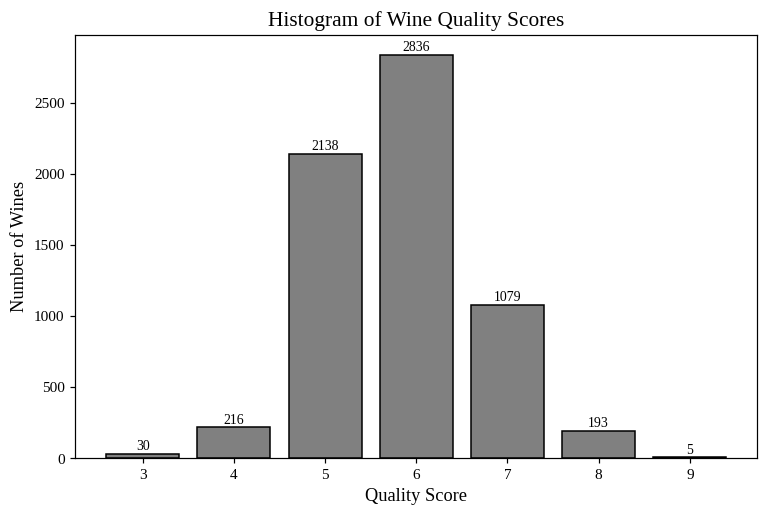

quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64
quality
3     0.46
4     3.32
5    32.91
6    43.65
7    16.61
8     2.97
9     0.08
Name: count, dtype: float64
Skewness: 0.19


In [32]:
quality_counts = wine["quality"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(quality_counts.index, quality_counts.values, color="gray", edgecolor="black", width=0.8)
for q, n in quality_counts.items():
    ax.text(q, n + 30, str(n), ha="center", fontsize=9)
ax.set_title("Histogram of Wine Quality Scores")
ax.set_xlabel("Quality Score")
ax.set_ylabel("Number of Wines")
ax.set_xticks(quality_counts.index)
save("cs5_quality_histogram")
print(quality_counts)
print((quality_counts / len(wine) * 100).round(2))
print("Skewness:", round(wine["quality"].skew(), 3))

### 2b. Box Plot of Alcohol by Quality

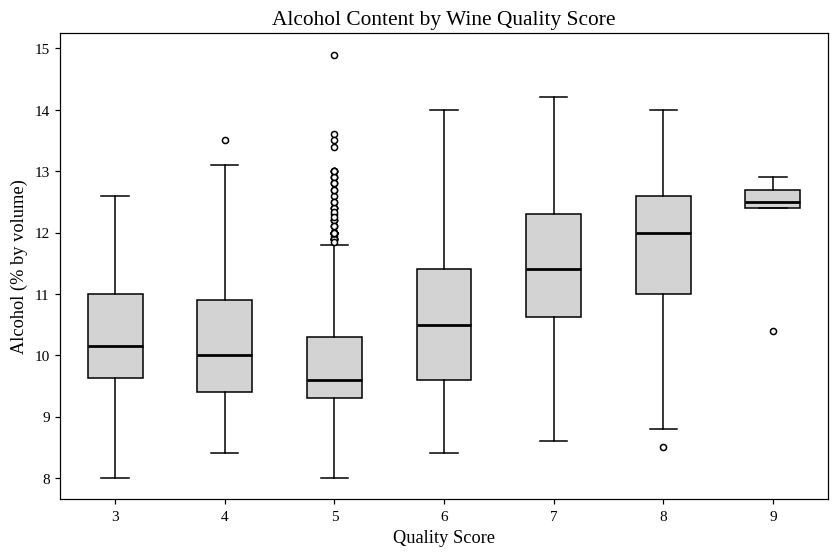

         count  median   mean
quality                      
3           30   10.15  10.22
4          216   10.00  10.18
5         2138    9.60   9.84
6         2836   10.50  10.59
7         1079   11.40  11.39
8          193   12.00  11.68
9            5   12.50  12.18
Quality 3 outliers: 0
Quality 4 outliers: 1
Quality 5 outliers: 55
Quality 6 outliers: 0
Quality 7 outliers: 0
Quality 8 outliers: 1
Quality 9 outliers: 1


In [33]:
quality_levels = sorted(wine["quality"].unique())
groups = [wine.loc[wine["quality"] == q, "alcohol"] for q in quality_levels]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.boxplot(groups, labels=quality_levels, patch_artist=True,
           boxprops=dict(facecolor="lightgray", color="black"),
           medianprops=dict(color="black", linewidth=1.8),
           whiskerprops=dict(color="black"),
           capprops=dict(color="black"),
           flierprops=dict(marker="o", markerfacecolor="white", markeredgecolor="black", markersize=4))
ax.set_title("Alcohol Content by Wine Quality Score")
ax.set_xlabel("Quality Score")
ax.set_ylabel("Alcohol (% by volume)")
save("cs5_alcohol_boxplot")
print(wine.groupby("quality")["alcohol"].agg(["count", "median", "mean"]).round(2))
for q, g in zip(quality_levels, groups):
    q1, q3 = g.quantile(0.25), g.quantile(0.75)
    iqr = q3 - q1
    n_out = ((g < q1 - 1.5 * iqr) | (g > q3 + 1.5 * iqr)).sum()
    print("Quality", q, "outliers:", n_out)

### 2c. Correlation Heatmap

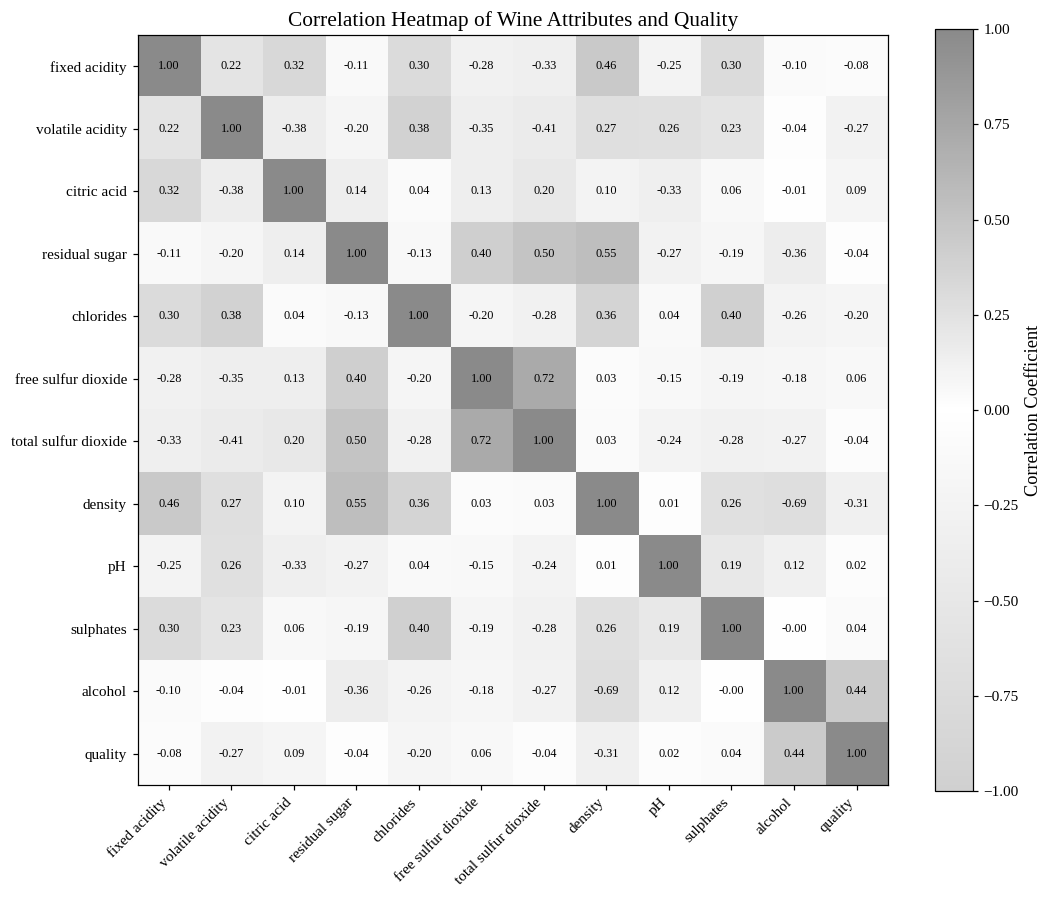

In [34]:
corr_wine = wine[attributes + ["quality"]].corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr_wine, cmap=GRAY_MAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_wine)))
ax.set_yticks(range(len(corr_wine)))
ax.set_xticklabels(corr_wine.columns, rotation=45, ha="right")
ax.set_yticklabels(corr_wine.columns)
for i in range(len(corr_wine)):
    for j in range(len(corr_wine)):
        ax.text(j, i, f"{corr_wine.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlation Heatmap of Wine Attributes and Quality")
fig.colorbar(im, ax=ax, label="Correlation Coefficient")
save("cs5_heatmap")

### 2d. Attributes Most Associated with Quality

In [35]:
quality_corr = corr_wine["quality"].drop("quality")
ranked = quality_corr.reindex(quality_corr.abs().sort_values(ascending=False).index)
print(ranked.round(4).to_string())

alcohol                 0.4443
density                -0.3059
volatile acidity       -0.2657
chlorides              -0.2007
citric acid             0.0855
fixed acidity          -0.0767
free sulfur dioxide     0.0555
total sulfur dioxide   -0.0414
sulphates               0.0385
residual sugar         -0.0370
pH                      0.0195


## Task 3: Predictive Modelling

### 3a and 3b. Model and Train-Test Split

In [36]:
X_wine = wine[attributes]
y_wine = wine["quality"]
X_train, X_test, y_train, y_test = train_test_split(X_wine, y_wine, test_size=0.2, random_state=42)
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
lin_model = LinearRegression().fit(X_train, y_train)
y_pred = lin_model.predict(X_test)

Training rows: 5197
Testing rows: 1300


### 3c. Test Set Metrics

In [37]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("MAE :", round(mae, 4))
print("MSE :", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R2  :", round(r2, 4))
print("Training R2:", round(lin_model.score(X_train, y_train), 4))
print("Within 0.5 of actual:", round((np.abs(y_test - y_pred) <= 0.5).mean() * 100, 1), "%")
print("Within 1.0 of actual:", round((np.abs(y_test - y_pred) <= 1.0).mean() * 100, 1), "%")

MAE : 0.5659
MSE : 0.5467
RMSE: 0.7394
R2  : 0.2598
Training R2: 0.2993
Within 0.5 of actual: 53.9 %
Within 1.0 of actual: 84.2 %


### 3d. Standardized Coefficients and Multicollinearity

In [38]:
std_coef = pd.Series(lin_model.coef_ * X_train.std().values / y_train.std(), index=attributes)
coef_table = pd.DataFrame({
    "Raw Coefficient": lin_model.coef_,
    "Standardized Coefficient": std_coef,
})
coef_table = coef_table.reindex(std_coef.abs().sort_values(ascending=False).index)
print("Intercept:", round(lin_model.intercept_, 4))
print(coef_table.round(4).to_string())

Intercept: 59.4198
                      Raw Coefficient  Standardized Coefficient
alcohol                        0.2707                    0.3678
residual sugar                 0.0459                    0.2514
volatile acidity              -1.3508                   -0.2499
density                      -58.9451                   -0.2023
total sulfur dioxide          -0.0027                   -0.1706
free sulfur dioxide            0.0070                    0.1398
sulphates                      0.8084                    0.1371
fixed acidity                  0.0790                    0.1161
pH                             0.4828                    0.0879
citric acid                   -0.1438                   -0.0237
chlorides                     -0.3328                   -0.0132


In [39]:
vif_rows = []
for col in attributes:
    others = [a for a in attributes if a != col]
    aux = LinearRegression().fit(X_wine[others], X_wine[col])
    r2_aux = aux.score(X_wine[others], X_wine[col])
    vif_rows.append({"Attribute": col, "VIF": 1 / (1 - r2_aux)})
vif_table = pd.DataFrame(vif_rows).set_index("Attribute").sort_values("VIF", ascending=False)
print(vif_table.round(2).to_string())

                        VIF
Attribute                  
density               15.91
residual sugar         7.23
fixed acidity          4.90
alcohol                4.78
total sulfur dioxide   2.94
pH                     2.54
free sulfur dioxide    2.14
volatile acidity       1.95
chlorides              1.63
citric acid            1.61
sulphates              1.54


In [40]:
print(corr_wine.loc[["density", "alcohol", "residual sugar", "total sulfur dioxide", "free sulfur dioxide"],
                    ["density", "alcohol", "residual sugar", "total sulfur dioxide", "free sulfur dioxide"]].round(3))

                      density  alcohol  residual sugar  total sulfur dioxide  \
density                 1.000   -0.687           0.553                 0.032   
alcohol                -0.687    1.000          -0.359                -0.266   
residual sugar          0.553   -0.359           1.000                 0.495   
total sulfur dioxide    0.032   -0.266           0.495                 1.000   
free sulfur dioxide     0.026   -0.180           0.403                 0.721   

                      free sulfur dioxide  
density                             0.026  
alcohol                            -0.180  
residual sugar                      0.403  
total sulfur dioxide                0.721  
free sulfur dioxide                 1.000  


### 3e. Predicted Versus Actual Scores

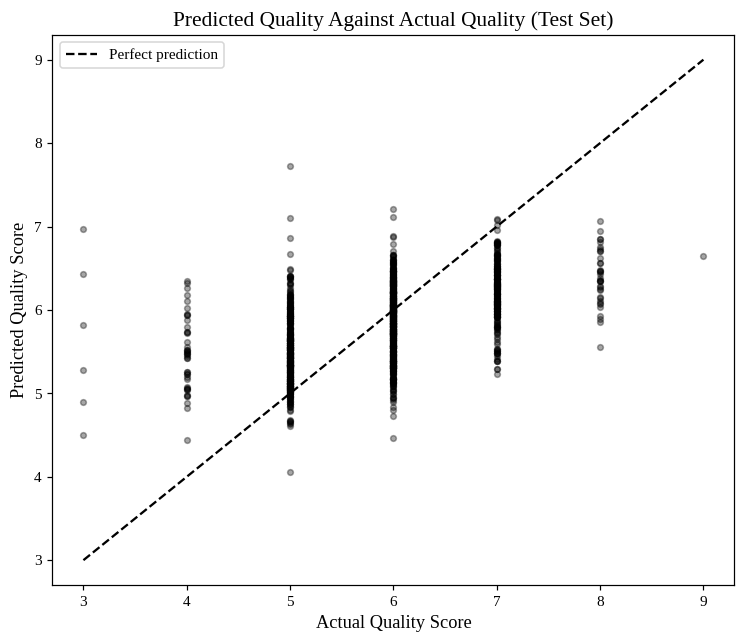

        count  mean
Actual             
3           6  5.65
4          43  5.48
5         402  5.51
6         597  5.86
7         215  6.20
8          36  6.39
9           1  6.65


In [41]:
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.scatter(y_test, y_pred, s=14, color="black", alpha=0.35)
ax.plot([3, 9], [3, 9], color="black", linestyle="--", label="Perfect prediction")
ax.set_title("Predicted Quality Against Actual Quality (Test Set)")
ax.set_xlabel("Actual Quality Score")
ax.set_ylabel("Predicted Quality Score")
ax.legend()
save("cs5_pred_vs_actual")
print(pd.DataFrame({"Actual": y_test, "Predicted": y_pred}).groupby("Actual")["Predicted"].agg(["count", "mean"]).round(2))

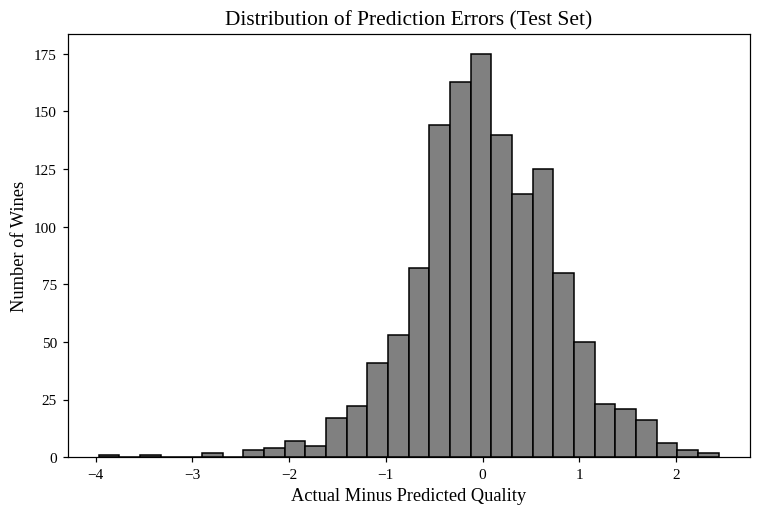

Mean error: 0.0244
Largest under-prediction: 2.44
Largest over-prediction: -3.97


In [42]:
residuals = y_test - y_pred
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(residuals, bins=30, color="gray", edgecolor="black")
ax.set_title("Distribution of Prediction Errors (Test Set)")
ax.set_xlabel("Actual Minus Predicted Quality")
ax.set_ylabel("Number of Wines")
save("cs5_residuals")
print("Mean error:", round(residuals.mean(), 4))
print("Largest under-prediction:", round(residuals.max(), 2))
print("Largest over-prediction:", round(residuals.min(), 2))

## Task 4: Business Decision-Making

In [43]:
baseline_rmse = np.sqrt(mean_squared_error(y_test, np.full(len(y_test), y_train.mean())))
print("Baseline RMSE (always predict the mean):", round(baseline_rmse, 4))
print("Model RMSE:", round(rmse, 4))
print("Improvement:", round((1 - rmse / baseline_rmse) * 100, 1), "%")

Baseline RMSE (always predict the mean): 0.8596
Model RMSE: 0.7394
Improvement: 14.0 %
